# 📘 12 — Exploratory Data Analysis
*Part of the Full Stack Data Science & AI booklet. Run cells top to bottom (Shift + Enter). Install libraries first: `pip install -r ../requirements.txt`.*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, sys, math, random, json, time, copy, warnings
from IPython.display import display
warnings.filterwarnings("ignore")

# 1️⃣3️⃣ EDA — Exploratory Data Analysis
**EDA = get to know your data before modelling.** Follow this checklist every time:
1. Shape, types, sample rows
2. Missing values & duplicates
3. Summary statistics
4. Univariate (one column) plots
5. Bivariate (two columns) plots & correlations
6. Outliers
7. Insights & next steps

## 🚀 Mini Project 9: EDA on Passenger Survival Data

In [2]:
df = pd.read_csv("data/passengers.csv")
print(df.shape); print(df.head()); df.info()
print("Missing:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df.describe(include="all").T)

(500, 6)
   pclass     sex   age   fare embarked  survived
0       1  female  37.0  91.98        S         1
1       3    male  33.0  15.87        Q         0
2       3    male  46.0  24.48        C         0
3       3    male  31.0  24.30      NaN         1
4       3  female  28.0  46.69        S         0
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    500 non-null    int64  
 1   sex       500 non-null    str    
 2   age       440 non-null    float64
 3   fare      500 non-null    float64
 4   embarked  495 non-null    str    
 5   survived  500 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 23.6 KB
Missing:
 pclass       0
sex          0
age         60
fare         0
embarked     5
survived     0
dtype: int64
Duplicates: 1
          count unique   top freq       mean        std    min      25%  \
pclass    500.0    NaN   

#### 🔍 How it works
- Step 1 of EDA is **profiling**: shape, types, missing counts, duplicates, `describe(include="all")` (`.T` flips it so each column is a row).
- Missing `age` is filled with the **median of the passenger's class** (`groupby("pclass")["age"].transform("median")`) — smarter than one global value because age differs by class. `mode()[0]` fills text gaps with the most common value.

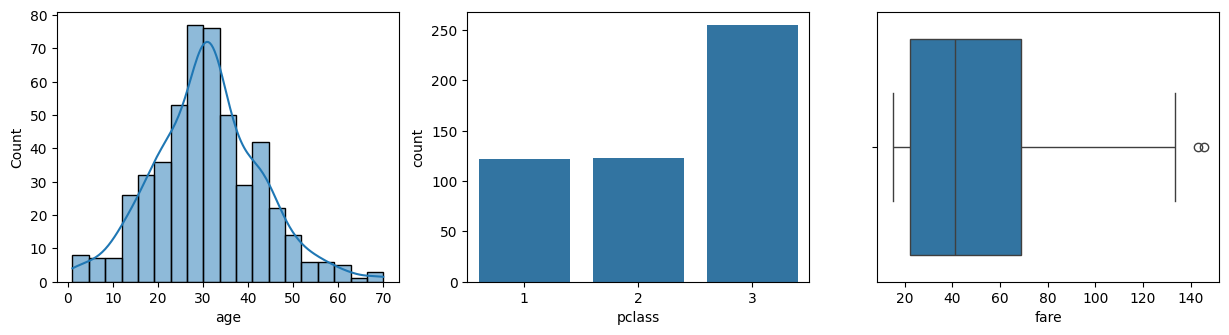

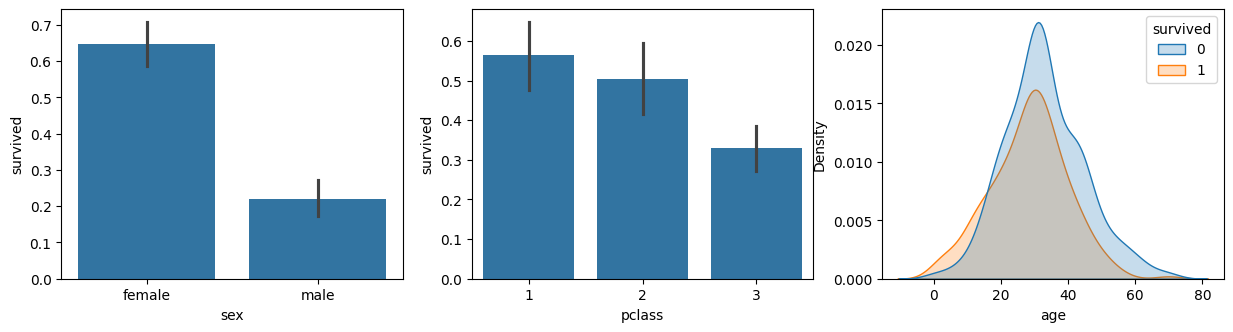

sex
female    0.65
male      0.22
Name: survived, dtype: float64
pclass
1    0.57
2    0.50
3    0.33
Name: survived, dtype: float64
Fare outliers: 2 rows (outside -47.6–138.6)


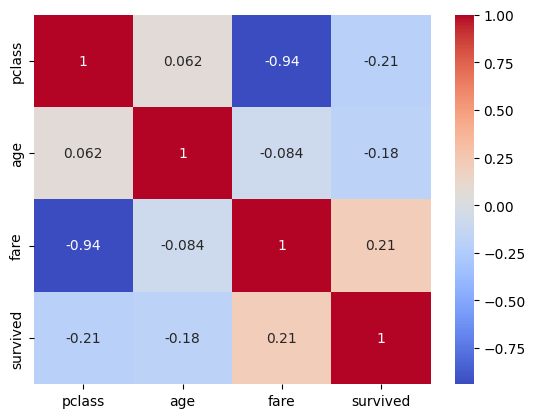

📌 Insights: women & first-class passengers survived more; younger age slightly helps.


In [3]:
# Cleaning
df["age"] = df["age"].fillna(df.groupby("pclass")["age"].transform("median"))
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

# Univariate
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(df.age, kde=True, ax=ax[0]); sns.countplot(data=df, x="pclass", ax=ax[1]); sns.boxplot(x=df.fare, ax=ax[2])
plt.show()

# Bivariate: who survived?
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.barplot(data=df, x="sex", y="survived", ax=ax[0]); sns.barplot(data=df, x="pclass", y="survived", ax=ax[1])
sns.kdeplot(data=df, x="age", hue="survived", fill=True, ax=ax[2]); plt.show()

print(df.groupby("sex").survived.mean().round(2), df.groupby("pclass").survived.mean().round(2), sep="\n")

# Outliers with IQR rule
q1, q3 = df.fare.quantile([.25, .75]); iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Fare outliers: {((df.fare < low) | (df.fare > high)).sum()} rows (outside {low:.1f}–{high:.1f})")
sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm"); plt.show()
print("📌 Insights: women & first-class passengers survived more; younger age slightly helps.")

#### 🔍 How the EDA charts and the outlier rule work
- `barplot(x="sex", y="survived")` → because survived is 0/1, the bar height = **survival rate**. `kdeplot(hue="survived", fill=True)` compares the age distribution of survivors vs non-survivors.
- **IQR outlier rule:** `IQR = Q3 − Q1`; a value is an outlier if it's below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR` (the same rule box-plot whiskers use).
- `select_dtypes("number").corr()` → correlation of numeric columns only.
#### 💼 Where it's used
EDA decides the whole project: which features matter, what to clean, whether the problem is even solvable. Always end EDA with **written insights** (the 📌 line), not just charts.